# Mini U-Net: from NIfTI files to a trained segmentation model
### Class example · data processing → training → testing

A small, complete pipeline that runs on a laptop CPU in a few minutes:

```
image + label files (.nii.gz)
  → 1. load with SimpleITK, reorient, check geometry
  → 2. normalise intensities
  → 3. split by PATIENT into train / val / test
  → 4. cut volumes into 2D slices, Dataset + augmentation
  → 5. 2D U-Net
  → 6. loss (BCE + Dice), training loop, validation
  → 7. test on whole volumes, 3D Dice, save prediction as NIfTI (with geometry!)
```

**Data:** the pelvic MR scans in `OrganData/`: 17 volumes, each an image/mask pair named like `001000_img.nii` and `001000_mask.nii`.
The masks contain 8 labelled organs (values 1–8); we train a **binary** U-Net for one of them, chosen with `LABEL_VALUE`.

In [1]:
# Run once if needed (then restart the kernel)
# %pip install torch SimpleITK numpy matplotlib pandas

## 0 · Setup and settings

In [2]:
import random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()     # Apple silicon
          else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.6.0 | device: mps


In [3]:
# ----------------------------- data -----------------------------
DATA_DIR    = "../../OrganDataProcessed"  # relative to this notebook (scripts/); or an absolute path
IMG_SUFFIX  = "_img"        # 001000_img.nii
LBL_SUFFIX  = "_mask"       # 001000_mask.nii
LABEL_VALUE = 6             # masks hold organs 1-8: pick one; None = all organs together as one foreground
                            # (labels 2, 3 and 8 are PAIRED organs, two blobs: see the note in step 7)
CT_WINDOW   = None          # MR scans have no fixed units (some 0-1, some 0-2000): use per-volume percentile clipping

# --------------------------- training ---------------------------
IMG_SIZE     = 128          # slices are resized to IMG_SIZE x IMG_SIZE (must be divisible by 16)
BATCH_SIZE   = 16
EPOCHS       = 20
LR           = 1e-3
VAL_FRAC     = 0.2
TEST_FRAC    = 0.2
KEEP_EMPTY   = 0.2          # fraction of slices WITHOUT foreground to keep for training

OUTPUT_DIR = Path("unet_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1 · Data: find image/label pairs

`OrganData/` holds 17 pelvic MR volumes from two groups (`001xxx`, `002xxx`), each with an integer mask of 8 organs.
Things to notice in the summary table below, because real data is messier than a tutorial:
* **Different scanners/protocols:** in-plane sizes from 180² to 512², spacing from 0.39 to 1 mm, slice thickness 2 to 3.6 mm.
* **Different intensity scales:** some images are already scaled to 0–1, others are raw scanner values up to ~2300. Per-volume normalisation (next step) is essential.
* Each file is treated as a separate patient when we split the data.

In [4]:
def find_pairs(folder):
    pairs = []
    for img_path in sorted(Path(folder).glob(f"*{IMG_SUFFIX}.nii*")):
        lbl_path = img_path.with_name(img_path.name.replace(IMG_SUFFIX, LBL_SUFFIX))
        if lbl_path.exists():
            pairs.append((img_path, lbl_path))
        else:
            print("No label found for", img_path.name, "-> skipped")
    return pairs

data_dir = Path(DATA_DIR)
if not data_dir.exists() and Path("OrganData").exists():   # notebook started from the course folder instead
    data_dir = Path("OrganData")
pairs = find_pairs(data_dir)
print(f"{len(pairs)} image/label pairs in {data_dir.resolve()}")
for p in pairs[:5]:
    print("  ", p[0].name, "+", p[1].name)
assert pairs, "No pairs found: check DATA_DIR and the suffixes"


17 image/label pairs in <teaching-data>/OrganDataProcessed
   001000_img.nii + 001000_mask.nii
   001001_img.nii + 001001_mask.nii
   001002_img.nii + 001002_mask.nii
   001003_img.nii + 001003_mask.nii
   001004_img.nii + 001004_mask.nii


## 2 · Load, reorient, check geometry, normalise

For every case:
1. Read image (as float32) and label with SimpleITK.
2. Reorient both to **LPS**, so slice *k* means the same thing in every scan.
3. **Check the label matches the image** (same size, spacing, origin). A mismatched label is a silent killer.
4. Normalise intensities: clip outliers, then zero mean and unit variance per volume.

In [5]:
def display_range(a):
    # Robust grey-level range for plotting: ignore the darkest 30% (air / background)
    body = a[a > np.percentile(a, 30)]
    return np.percentile(body if body.size else a, [1, 99.5])

def normalise(arr, window=None):
    lo, hi = window if window is not None else np.percentile(arr, [0.5, 99.5])
    arr = np.clip(arr, lo, hi)
    return ((arr - arr.mean()) / (arr.std() + 1e-8)).astype(np.float32)

def load_case(img_path, lbl_path):
    img_raw = sitk.ReadImage(str(img_path), sitk.sitkFloat32)
    lbl_raw = sitk.ReadImage(str(lbl_path))
    try:
        orig_code = sitk.DICOMOrientImageFilter.GetOrientationFromDirectionCosines(img_raw.GetDirection())
    except Exception:
        orig_code = None
    img = sitk.DICOMOrient(img_raw, "LPS")
    lbl = sitk.DICOMOrient(lbl_raw, "LPS")

    # --- geometry checks ---
    assert img.GetSize() == lbl.GetSize(), f"{img_path.name}: size {img.GetSize()} vs label {lbl.GetSize()}"
    if not (np.allclose(img.GetSpacing(), lbl.GetSpacing(), atol=1e-3)
            and np.allclose(img.GetOrigin(), lbl.GetOrigin(), atol=1e-2)):
        print(f"WARNING {img_path.name}: label geometry differs from image")

    arr = sitk.GetArrayFromImage(img)                      # (z, y, x)
    lab = sitk.GetArrayFromImage(lbl)
    lab = (lab == LABEL_VALUE) if LABEL_VALUE is not None else (lab > 0)
    return {"name": img_path.name.replace(IMG_SUFFIX, "").split(".")[0],
            "image": img, "orig_code": orig_code,
            "raw": arr, "arr": normalise(arr, CT_WINDOW), "lab": lab.astype(np.uint8)}

cases = [load_case(i, l) for i, l in pairs]

summary = pd.DataFrame([{
    "case": c["name"], "label values": np.unique(sitk.GetArrayViewFromImage(sitk.ReadImage(str(p[1])))).astype(int).tolist(),
    "shape (z,y,x)": c["arr"].shape,
    "spacing (x,y,z)": tuple(round(s, 2) for s in c["image"].GetSpacing()),
    "orig orientation": c["orig_code"],
    "fg slices": int(c["lab"].any(axis=(1, 2)).sum()),
    "fg volume (ml)": round(c["lab"].sum() * np.prod(c["image"].GetSpacing()) / 1000, 1),
} for c, p in zip(cases, pairs)])
summary

,case,label values,"shape (z,y,x)","spacing (x,y,z)",orig orientation,fg slices,fg volume (ml)
0,001000,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,36,70.2
1,001001,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,45,77.2
2,001002,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,36,50.8
3,001003,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,40,28.8
4,001004,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,36,30.7
5,001005,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,36,36.0
6,001006,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,46,35.0
7,002000,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,36,44.4
8,002002,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,43,34.1
9,002003,"[0, 1, 2, 3, 4, 5, 6, 7, 8]","(48, 192, 192)","(1.0, 1.0, 2.0)",LPS,36,43.8


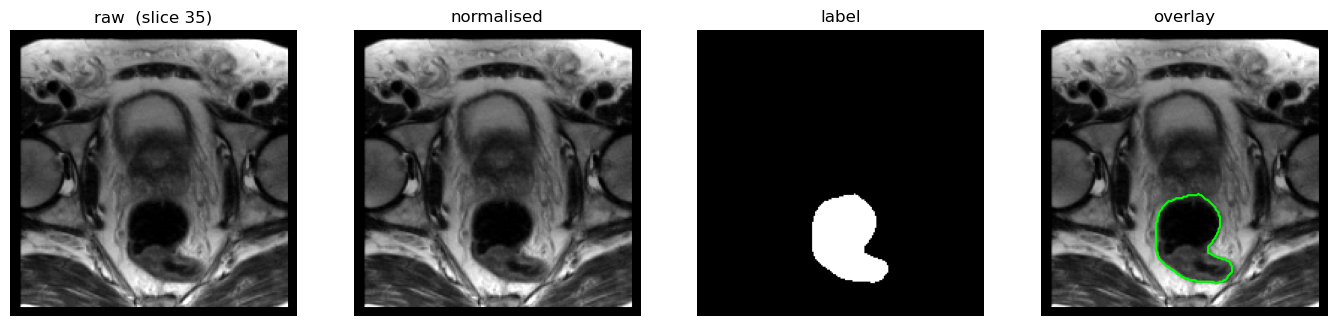

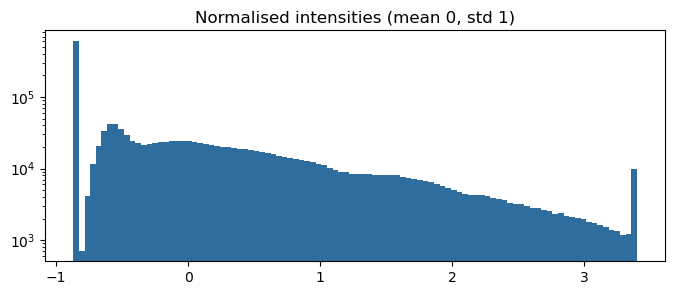

In [6]:
# Look before you train: image, label and their overlay on the slice with the most foreground
c = cases[0]
k = int(c["lab"].sum(axis=(1, 2)).argmax())
sx, sy, _ = c["image"].GetSpacing()
vr, vn = display_range(c["raw"]), display_range(c["arr"])
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
axes[0].imshow(c["raw"][k], cmap="gray", aspect=sy / sx, vmin=vr[0], vmax=vr[1]); axes[0].set_title(f"raw  (slice {k})")
axes[1].imshow(c["arr"][k], cmap="gray", aspect=sy / sx, vmin=vn[0], vmax=vn[1]); axes[1].set_title("normalised")
axes[2].imshow(c["lab"][k], cmap="gray", aspect=sy / sx); axes[2].set_title("label")
axes[3].imshow(c["arr"][k], cmap="gray", aspect=sy / sx, vmin=vn[0], vmax=vn[1])
axes[3].contour(c["lab"][k], levels=[0.5], colors="lime", linewidths=1.5); axes[3].set_title("overlay")
for ax in axes: ax.axis("off")
plt.show()

plt.figure(figsize=(8, 3))
plt.hist(c["arr"].ravel(), bins=100, color="#2f6d9e")
plt.title("Normalised intensities (mean 0, std 1)"); plt.yscale("log"); plt.show()

## 3 · Split by patient, not by slice

⚠️ Neighbouring slices of one scan look almost identical. If slices from the same patient land in both train and test, the test score is **inflated** (data leakage).
So we split **whole volumes** into train / val / test first, and only then cut them into slices.

With fewer than 3 volumes a patient-level split is impossible. The code then splits each volume into three slabs along z and warns you: fine for a demo, not a fair evaluation.

In [7]:
def split_cases(cases, val_frac=VAL_FRAC, test_frac=TEST_FRAC, seed=SEED):
    if len(cases) < 3:
        print(f"WARNING: only {len(cases)} volume(s). Splitting each volume into slabs along z "
              "(train 60% / val 20% / test 20%). Test slices are neighbours of training slices!")
        tr, va, te = [], [], []
        for c in cases:
            nz = c["arr"].shape[0]
            a, b = int(0.6 * nz), int(0.8 * nz)
            for part, (z0, z1) in zip((tr, va, te), [(0, a), (a, b), (b, nz)]):
                part.append({**c, "name": f'{c["name"]}[z{z0}:{z1}]',
                             "image": c["image"][:, :, z0:z1],      # SimpleITK slicing keeps geometry
                             "raw": c["raw"][z0:z1], "arr": c["arr"][z0:z1], "lab": c["lab"][z0:z1]})
        return tr, va, te
    idx = np.random.default_rng(seed).permutation(len(cases))
    n_test = max(1, round(test_frac * len(cases)))
    n_val = max(1, round(val_frac * len(cases)))
    te = [cases[i] for i in idx[:n_test]]
    va = [cases[i] for i in idx[n_test:n_test + n_val]]
    tr = [cases[i] for i in idx[n_test + n_val:]]
    return tr, va, te

train_cases, val_cases, test_cases = split_cases(cases)
for name, part in [("train", train_cases), ("val", val_cases), ("test", test_cases)]:
    print(f"{name:5s}: {len(part):2d} volumes  {[c['name'] for c in part]}")

train: 11 volumes  ['002000', '001005', '002010', '002006', '002007', '001006', '002003', '002008', '002002', '001001', '002009']
val  :  3 volumes  ['002005', '001000', '001004']
test :  3 volumes  ['001002', '002004', '001003']


## 4 · From volumes to 2D slices, Dataset and DataLoader

* A **2D** U-Net sees one axial slice at a time: fast, with little memory, and plenty of training samples.
* Most slices contain no foreground. We keep all foreground slices and only `KEEP_EMPTY` of the empty ones, so the network is not swamped by background.
* Slices are resized to `IMG_SIZE × IMG_SIZE`, with **bilinear** interpolation for images and **nearest** for labels (labels must stay 0/1).
* **Augmentation** (training only): random flips, 90° rotations and small intensity changes, which give "new" samples for free.

In [8]:
def extract_slices(case_list, keep_empty=1.0, seed=SEED):
    rng = np.random.default_rng(seed)
    X, Y = [], []
    for c in case_list:
        for k in range(c["arr"].shape[0]):
            if c["lab"][k].any() or rng.random() < keep_empty:
                X.append(c["arr"][k]); Y.append(c["lab"][k])
    return X, Y

class SliceDataset(Dataset):
    def __init__(self, images, labels, size=IMG_SIZE, augment=False):
        self.images, self.labels, self.size, self.augment = images, labels, size, augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        x = torch.from_numpy(np.ascontiguousarray(self.images[i]))[None, None]            # (1, 1, H, W)
        y = torch.from_numpy(self.labels[i].astype(np.float32))[None, None]
        x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)[0]
        y = F.interpolate(y, size=(self.size, self.size), mode="nearest")[0]                # stays 0/1
        if self.augment:
            if random.random() < 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() < 0.5: x, y = x.flip(-2), y.flip(-2)
            r = random.randint(0, 3)
            x, y = torch.rot90(x, r, (-2, -1)), torch.rot90(y, r, (-2, -1))
            x = x * (1 + 0.1 * torch.randn(1)) + 0.1 * torch.randn(1)                       # contrast/brightness
        return x, y                                                                          # (1, S, S) each

Xtr, Ytr = extract_slices(train_cases, keep_empty=KEEP_EMPTY)
Xva, Yva = extract_slices(val_cases)            # validate on ALL slices: closer to real use
train_ds = SliceDataset(Xtr, Ytr, augment=True)
val_ds   = SliceDataset(Xva, Yva)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

fg = np.mean([y.any() for y in Ytr])
print(f"train slices: {len(train_ds)} ({fg:.0%} with foreground) | val slices: {len(val_ds)}")
xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| label values:", yb.unique().tolist())

train slices: 458 (97% with foreground) | val slices: 144
one batch: (16, 1, 128, 128) (16, 1, 128, 128) | label values: [0.0, 1.0]


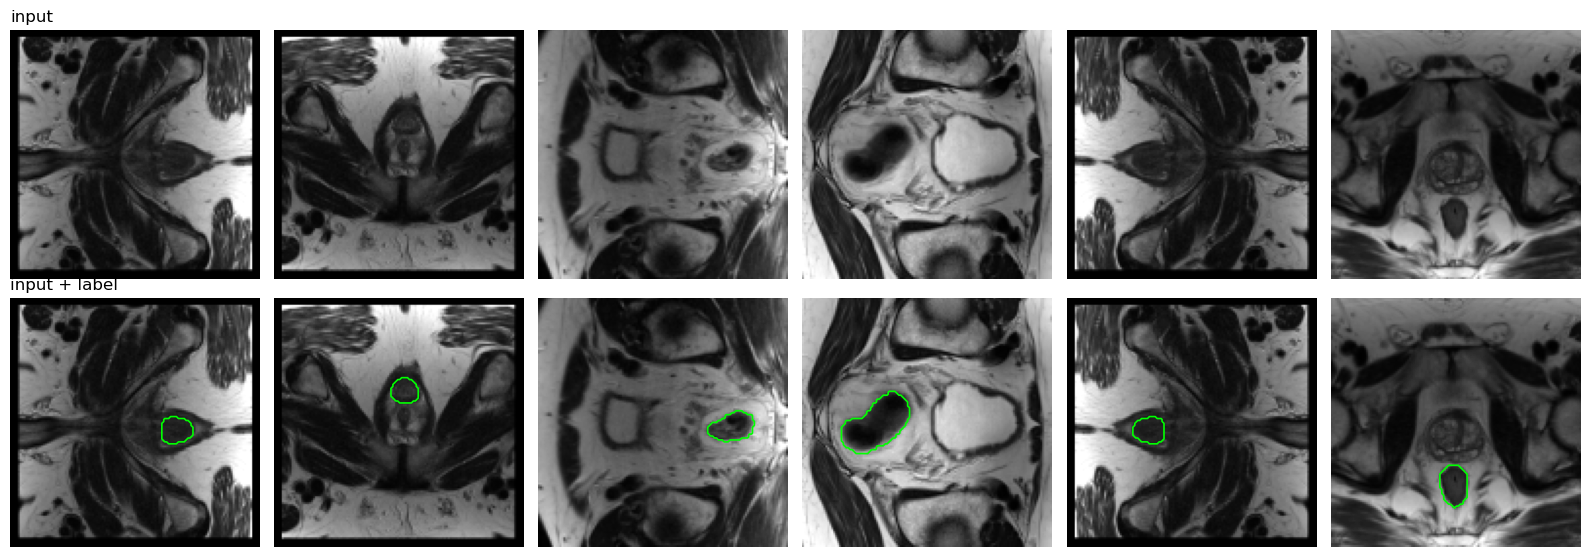

In [9]:
# What the network actually sees: augmented training samples
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for n in range(6):
    x, y = train_ds[random.randrange(len(train_ds))]
    axes[0, n].imshow(x[0], cmap="gray"); axes[0, n].axis("off")
    axes[1, n].imshow(x[0], cmap="gray"); axes[1, n].axis("off")
    if y.sum() > 0:
        axes[1, n].contour(y[0], levels=[0.5], colors="lime", linewidths=1.2)
axes[0, 0].set_title("input", loc="left"); axes[1, 0].set_title("input + label", loc="left")
plt.tight_layout(); plt.show()

## 5 · The U-Net

```
input 128² ─ DoubleConv(16) ────────────────────────────── skip ──→ cat → DoubleConv(16) → 1×1 conv → logits 128²
               ↓ pool                                                  ↑ up
             DoubleConv(32) ───────────────────── skip ──→ cat → DoubleConv(32)
               ↓ pool                                         ↑ up
             DoubleConv(64) ──────────── skip ──→ cat → DoubleConv(64)
               ↓ pool                                ↑ up
             DoubleConv(128) ─── skip ──→ cat → DoubleConv(128)
               ↓ pool                       ↑ up
             DoubleConv(256)   (bottleneck: 8×8, most context)
```

* **Encoder** (left): convolutions + pooling learn *what* is in the image, at lower and lower resolution.
* **Decoder** (right): up-convolutions recover the resolution.
* **Skip connections** copy encoder features across, so the decoder knows *where* edges are. This is the key idea of U-Net.
* The output is one **logit** per pixel; `sigmoid(logit)` is the probability of foreground.

In [ ]:
class DoubleConv(nn.Sequential):
    # (conv 3x3 -> BatchNorm -> ReLU) x 2
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=8, depth=4):
        super().__init__()
        ch = [base * 2 ** i for i in range(depth + 1)]                     # 16, 32, 64, 128, 256
        self.down = nn.ModuleList([DoubleConv(in_ch, ch[0])] +
                                  [DoubleConv(ch[i], ch[i + 1]) for i in range(depth)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2)
                                 for i in reversed(range(depth))])
        self.up_conv = nn.ModuleList([DoubleConv(2 * ch[i], ch[i]) for i in reversed(range(depth))])
        self.head = nn.Conv2d(ch[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for i, block in enumerate(self.down):
            x = block(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()                                                   # bottleneck
        for up, conv in zip(self.up, self.up_conv):
            x = up(x)
            x = conv(torch.cat([skips.pop(), x], dim=1))                  # skip connection
        return self.head(x)                                               # logits

model = UNet().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"U-Net with {n_params / 1e6:.2f} M parameters")
with torch.no_grad():
    print("output shape for one batch:", tuple(model(xb.to(DEVICE)).shape))

U-Net with 1.94 M parameters
output shape for one batch: (16, 1, 128, 128)


## 6 · Loss, metric and training

* **Binary cross-entropy (BCE)** judges every pixel separately: stable, but with 98% background a network can score well by predicting "background" everywhere.
* **Dice loss** measures overlap, `Dice = 2|A∩B| / (|A| + |B|)`, so it focuses on the foreground. We use **BCE + Dice**.
* Each epoch we **validate** on the val slices and keep the weights with the best **val Dice**. That is the model we test.

In [11]:
class DiceBCELoss(nn.Module):
    def forward(self, logits, target, smooth=1.0):
        bce = F.binary_cross_entropy_with_logits(logits, target)
        p = torch.sigmoid(logits)
        inter = (p * target).sum(dim=(1, 2, 3))
        denom = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
        dice = (2 * inter + smooth) / (denom + smooth)
        return bce + (1 - dice.mean())

def dice_score(pred, gt):
    # Dice of two binary numpy arrays (any shape). Both empty -> 1.
    pred, gt = pred.astype(bool), gt.astype(bool)
    s = pred.sum() + gt.sum()
    return 1.0 if s == 0 else 2.0 * (pred & gt).sum() / s

criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

In [12]:
history = {"train_loss": [], "val_loss": [], "val_dice": []}
best_dice, best_path = -1.0, OUTPUT_DIR / "best_unet.pt"

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    # ---- train ----
    model.train()
    train_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(x)
    train_loss /= len(train_ds)

    # ---- validate ----
    model.eval()
    val_loss, inter, denom = 0.0, 0.0, 0.0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            val_loss += criterion(logits, y).item() * len(x)
            pred = (torch.sigmoid(logits) > 0.5).float()
            inter += (pred * y).sum().item()
            denom += pred.sum().item() + y.sum().item()
    val_loss /= len(val_ds)
    val_dice = 2 * inter / denom if denom > 0 else 1.0
    scheduler.step(val_dice)

    for key, v in zip(history, (train_loss, val_loss, val_dice)):
        history[key].append(v)
    flag = ""
    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), best_path)
        flag = "  <- best, saved"
    print(f"epoch {epoch:3d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
          f"val Dice {val_dice:.3f} | {time.time() - t0:5.1f}s{flag}")

print(f"\nBest val Dice: {best_dice:.3f}  (weights in {best_path})")

epoch   1 | train loss 1.5041 | val loss 2.5040 | val Dice 0.053 |   8.0s  <- best, saved
epoch   2 | train loss 1.3980 | val loss 1.5235 | val Dice 0.141 |   1.7s  <- best, saved
epoch   3 | train loss 1.3367 | val loss 1.3433 | val Dice 0.070 |   1.6s
epoch   4 | train loss 1.2790 | val loss 1.2310 | val Dice 0.344 |   1.7s  <- best, saved
epoch   5 | train loss 1.1921 | val loss 1.2462 | val Dice 0.199 |   1.6s
epoch   6 | train loss 1.0964 | val loss 1.1017 | val Dice 0.448 |   1.6s  <- best, saved
epoch   7 | train loss 1.0160 | val loss 1.0096 | val Dice 0.695 |   1.7s  <- best, saved
epoch   8 | train loss 0.9444 | val loss 0.9566 | val Dice 0.747 |   1.7s  <- best, saved
epoch   9 | train loss 0.8708 | val loss 0.9370 | val Dice 0.729 |   1.7s
epoch  10 | train loss 0.8020 | val loss 0.8931 | val Dice 0.575 |   1.6s
epoch  11 | train loss 0.7324 | val loss 0.8113 | val Dice 0.652 |   1.6s
epoch  12 | train loss 0.6479 | val loss 0.7357 | val Dice 0.782 |   1.7s  <- best, saved


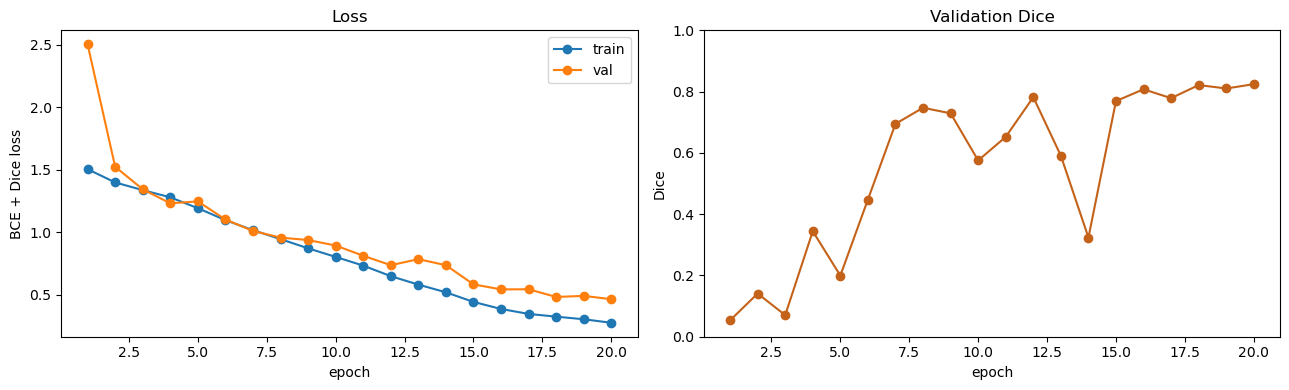

In [13]:
ep = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ep, history["train_loss"], "o-", label="train")
axes[0].plot(ep, history["val_loss"], "o-", label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE + Dice loss"); axes[0].legend(); axes[0].set_title("Loss")
axes[1].plot(ep, history["val_dice"], "o-", color="#c4621a")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("Dice"); axes[1].set_ylim(0, 1); axes[1].set_title("Validation Dice")
plt.tight_layout(); plt.show()

**Reading the curves:** both losses going down means it is learning. Train loss going down while val loss goes **up** means it is **overfitting**: more data, more augmentation, or stop earlier.

## 7 · Testing on whole volumes

Testing must look like real use:
1. Load the **best** weights and switch to `model.eval()` (fixes BatchNorm, no gradients).
2. Predict **every** slice of each test volume, resize back to the original size, and stack into 3D.
3. Threshold at 0.5 and compute the **3D Dice** per volume.
4. Optional post-processing: keep the **largest connected component**. Only do this for an organ that is one object: for the paired labels 2, 3 and 8 it would delete one side, so compare the two Dice columns.
5. Save the prediction as NIfTI with **`CopyInformation`**, so it overlays on the scan in ITK-SNAP or 3D Slicer.

In [14]:
model.load_state_dict(torch.load(best_path, map_location=DEVICE))
model.eval()

@torch.no_grad()
def predict_volume(model, arr, size=IMG_SIZE, batch=16):
    # arr: normalised (z, y, x) volume -> foreground probability, same shape
    nz, H, W = arr.shape
    probs = np.zeros((nz, H, W), np.float32)
    for s in range(0, nz, batch):
        x = torch.from_numpy(np.ascontiguousarray(arr[s:s + batch]))[:, None].to(DEVICE)
        x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
        p = torch.sigmoid(model(x))
        p = F.interpolate(p, size=(H, W), mode="bilinear", align_corners=False)
        probs[s:s + batch] = p[:, 0].cpu().numpy()
    return probs

def largest_component(mask_arr, ref_image):
    m = sitk.GetImageFromArray(mask_arr.astype(np.uint8))
    m.CopyInformation(ref_image)
    cc = sitk.RelabelComponent(sitk.ConnectedComponent(m), sortByObjectSize=True)
    return (sitk.GetArrayFromImage(cc) == 1).astype(np.uint8)

def save_like(arr, ref_image, path, orig_code=None):
    out = sitk.GetImageFromArray(arr)
    out.CopyInformation(ref_image)                 # <- geometry from the scan (lecture, slide 9!)
    if orig_code:
        out = sitk.DICOMOrient(out, orig_code)     # back to the scan's original orientation
    sitk.WriteImage(out, str(path))

pred_dir = OUTPUT_DIR / "predictions"
pred_dir.mkdir(exist_ok=True)
rows = []
for c in test_cases:
    t0 = time.time()
    prob = predict_volume(model, c["arr"])
    pred = (prob > 0.5).astype(np.uint8)
    pred_lcc = largest_component(pred, c["image"]) if pred.any() else pred
    c["prob"], c["pred"] = prob, pred_lcc
    vox_ml = np.prod(c["image"].GetSpacing()) / 1000
    rows.append({"case": c["name"],
                 "Dice": round(dice_score(pred, c["lab"]), 3),
                 "Dice (largest comp.)": round(dice_score(pred_lcc, c["lab"]), 3),
                 "GT ml": round(c["lab"].sum() * vox_ml, 1),
                 "pred ml": round(pred_lcc.sum() * vox_ml, 1),
                 "seconds": round(time.time() - t0, 2)})
    safe = c["name"].replace("[", "_").replace("]", "").replace(":", "-")
    save_like(pred_lcc, c["image"], pred_dir / f"{safe}_pred.nii.gz", c.get("orig_code"))
    save_like(prob, c["image"], pred_dir / f"{safe}_prob.nii.gz", c.get("orig_code"))

results = pd.DataFrame(rows)
results.to_csv(OUTPUT_DIR / "test_results.csv", index=False)
print(f"mean test Dice: {results['Dice (largest comp.)'].mean():.3f}   |  predictions saved in {pred_dir}")
results

mean test Dice: 0.787   |  predictions saved in unet_outputs/predictions


,case,Dice,Dice (largest comp.),GT ml,pred ml,seconds
0,001002,0.734,0.749,50.8,70.4,0.29
1,002004,0.835,0.835,51.5,64.7,0.05
2,001003,0.776,0.776,28.8,32.9,0.05


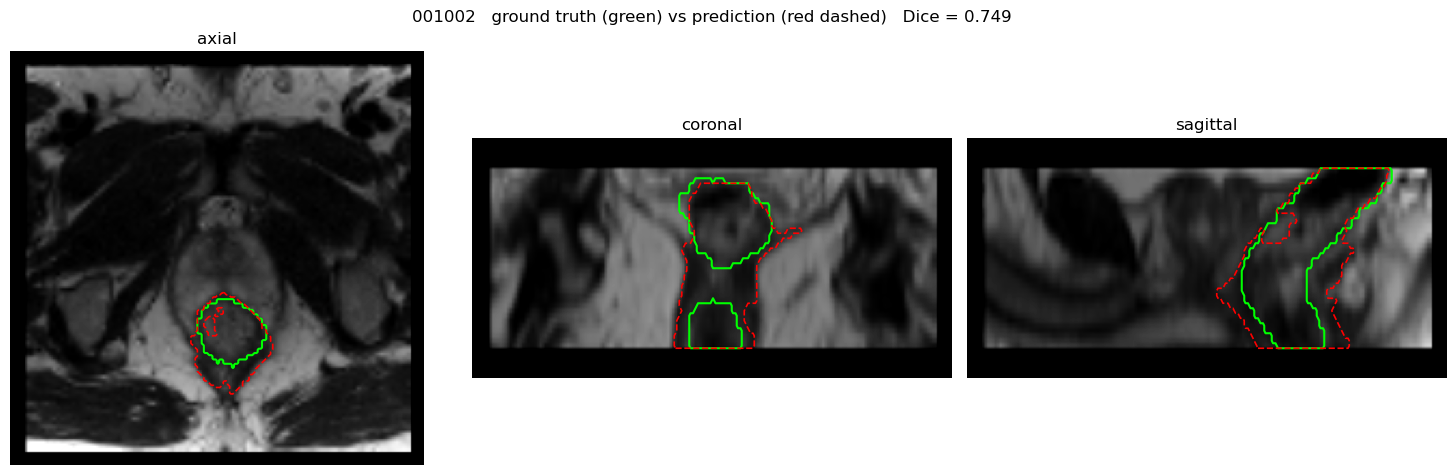

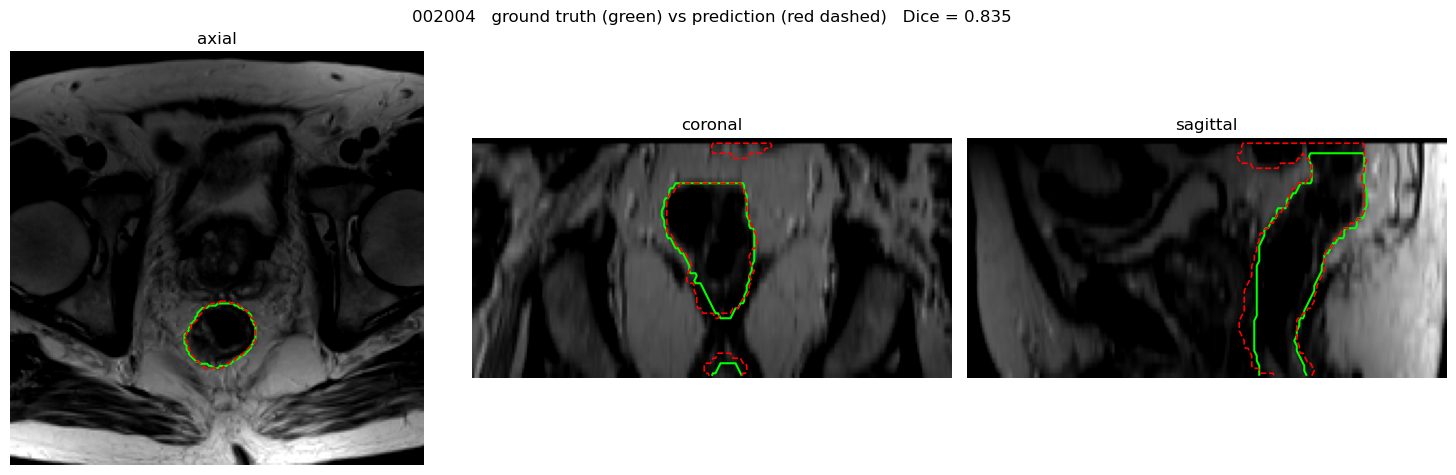

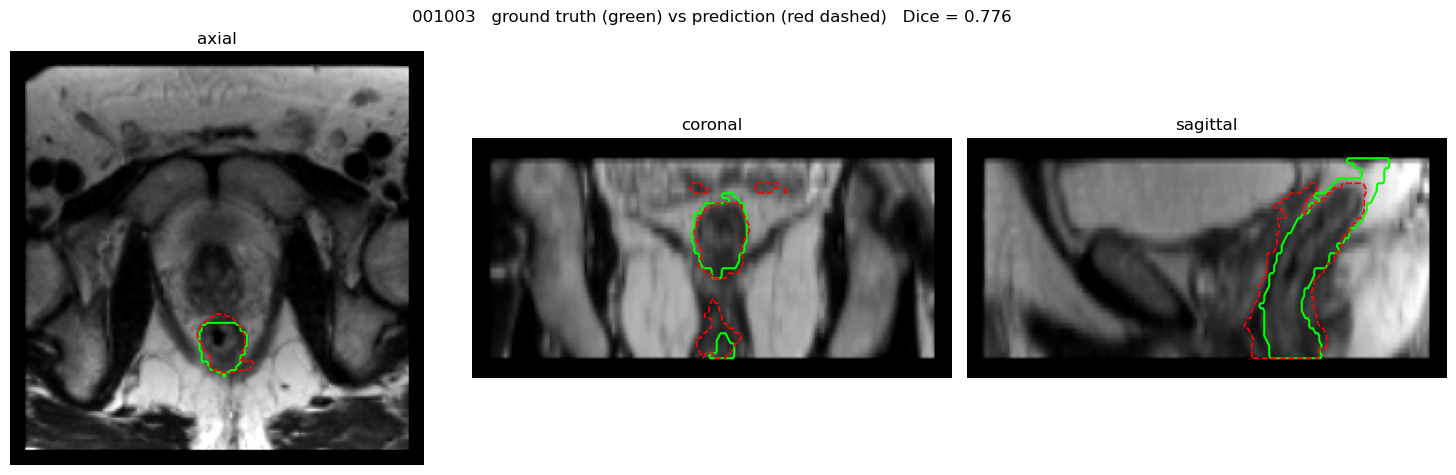

In [15]:
def show_result(c, title=""):
    # Axial, coronal and sagittal views through the centre of the ground truth: GT green, prediction red
    arr, gt, pr = c["arr"], c["lab"], c["pred"]
    sx, sy, sz = c["image"].GetSpacing()
    if gt.any():
        k, j, i = np.round(np.argwhere(gt).mean(axis=0)).astype(int)
    else:
        k, j, i = (s // 2 for s in arr.shape)
    views = [("axial", arr[k], gt[k], pr[k], sy / sx, "upper"),
             ("coronal", arr[:, j], gt[:, j], pr[:, j], sz / sx, "lower"),
             ("sagittal", arr[:, :, i], gt[:, :, i], pr[:, :, i], sz / sy, "lower")]
    lo, hi = display_range(arr)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    for ax, (name, im, g, p, asp, org) in zip(axes, views):
        ax.imshow(im, cmap="gray", aspect=asp, origin=org, vmin=lo, vmax=hi)
        if g.any(): ax.contour(g, levels=[0.5], colors="lime", linewidths=1.5)
        if p.any(): ax.contour(p, levels=[0.5], colors="red", linewidths=1.2, linestyles="--")
        ax.set_title(name); ax.axis("off")
    fig.suptitle(title or f'{c["name"]}   ground truth (green) vs prediction (red dashed)   '
                          f'Dice = {dice_score(pr, gt):.3f}')
    plt.tight_layout(); plt.show()

for c in test_cases:
    show_result(c)

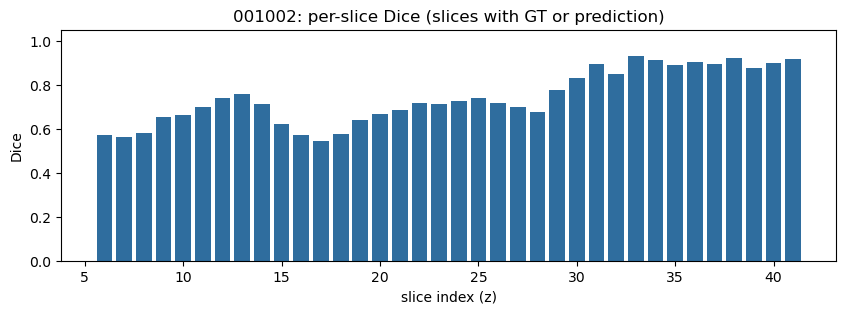

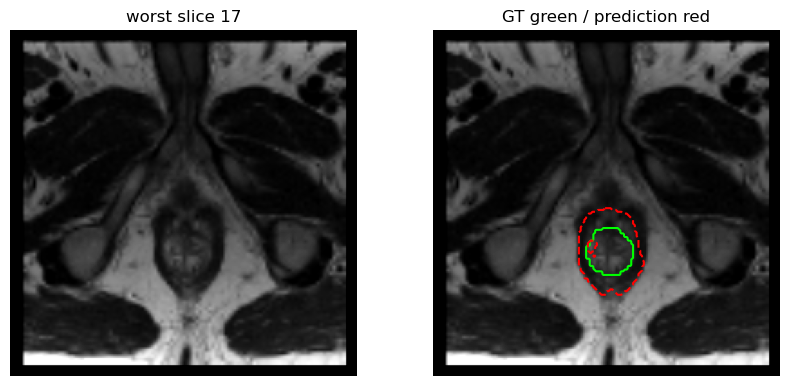

In [16]:
# Where does it go wrong? Per-slice Dice for the first test volume
c = test_cases[0]
fg_slices = [k for k in range(c["lab"].shape[0]) if c["lab"][k].any() or c["pred"][k].any()]
per_slice = [dice_score(c["pred"][k], c["lab"][k]) for k in fg_slices]
plt.figure(figsize=(10, 3))
plt.bar(fg_slices, per_slice, color="#2f6d9e")
plt.xlabel("slice index (z)"); plt.ylabel("Dice"); plt.ylim(0, 1.05)
plt.title(f'{c["name"]}: per-slice Dice (slices with GT or prediction)')
plt.show()
if per_slice:
    worst = fg_slices[int(np.argmin(per_slice))]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
    lo, hi = display_range(c["arr"])
    ax[0].imshow(c["arr"][worst], cmap="gray", vmin=lo, vmax=hi); ax[0].set_title(f"worst slice {worst}")
    ax[1].imshow(c["arr"][worst], cmap="gray", vmin=lo, vmax=hi)
    if c["lab"][worst].any(): ax[1].contour(c["lab"][worst], levels=[0.5], colors="lime")
    if c["pred"][worst].any(): ax[1].contour(c["pred"][worst], levels=[0.5], colors="red", linestyles="--")
    ax[1].set_title("GT green / prediction red")
    for a in ax: a.axis("off")
    plt.show()

Open the scan together with `unet_outputs/predictions/*_pred.nii.gz` in **ITK-SNAP** or **3D Slicer**. The prediction should sit exactly on the anatomy, because we saved it with the scan's geometry.

## 8 · Exercises and next steps

1. **Leakage experiment.** Split by *slice* instead of by patient and compare the test Dice. Why is it higher, and why is it misleading?
2. **Loss.** Train with BCE only, then Dice only. Which converges faster, and which gives the better Dice?
3. **Augmentation.** Turn `augment=False`. What happens to the gap between train and val loss?
4. **Capacity.** Try `UNet(base=8)` and `UNet(base=32)`. Compare parameters, speed and Dice.
5. **Threshold.** Is 0.5 the best threshold? Try 0.3 to 0.7 on the **validation** set (never tune on test!).
6. **Resolution.** Change `IMG_SIZE` to 64 and 256. What happens to small structures?
7. **Other organs.** Change `LABEL_VALUE` (1–8). Which organs are easy, which are hard, and does organ size explain it?
8. **Multi-class.** Segment all 8 organs at once: use `out_ch=9` (background + 8) with `nn.CrossEntropyLoss` and `argmax` instead of the sigmoid, with the raw mask values as targets.

**Where to go from here**
* **2.5D / 3D U-Net**: give the network neighbouring slices, or whole 3D patches (`nn.Conv3d`).
* **MONAI** (`pip install monai`): medical-imaging PyTorch library with ready-made transforms, U-Nets and Dice metrics.
* **nnU-Net**: a self-configuring U-Net pipeline, the standard strong baseline for segmentation challenges.